
# Bluebikes Rebalancing Optimization — Greater Boston

**Course:** DADS 5250 — Generative AI  
**Assignment:** Module 7 Hackathon

**Team Members:**
- Aditi Rao
- Satoshi Nakamura
- Vinay Manikandan Nagarajan

## Project Objective

Develop an AI-assisted application that analyzes historical
Bluebikes trip data, forecasts bike redistribution needs
across Greater Boston for 2026, and recommends staffing
levels to support daily operations.

## Project Components

1. Data Preparation and Demand Forecasting
2. Staffing Optimization and Cost Analysis
3. GenAI Event Analysis
4. Backtesting and Sensitivity Analysis

## Data Sources

- Bluebikes Historical Trip Data
- Bluebikes Station Information

## AI Assistance Disclosure

I used AI to assist with code streamlining,
debugging, and explanations.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
import zipfile
import io
import calendar

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Data Preparation

In [3]:
# Load the official Bluebikes station list
station_url = (
    "https://assets.ctfassets.net/p6ae3zqfb1e3/"
    "3BswRZgQMp0f8XWBLY6T19/"
    "60da57a4630102788a127902bfda9888/"
    "-External-_Bluebikes_Station_List__updated_08.21.26_.csv"
)

stations = pd.read_csv(station_url, skiprows=1)

# Check the dataset
print("Number of stations:", len(stations))
print("\nColumn names:")
print(stations.columns.tolist())

# Preview the first 5 rows
display(stations.head())

Number of stations: 613

Column names:
['Name', 'Lat', 'Long', 'Seasonal Status', 'Municipality', 'Total Docks', 'Station ID (to match to historic system data)']


,Name,Lat,Long,Seasonal Status,Municipality,Total Docks,Station ID (to match to historic system data)
0,Myrtle St at Fellsway (Rt 28),42.416235,-71.085073,Year Round,Medford,15,No ID post-March 2023
1,Webster Ave at Norfolk St,42.374606,-71.094757,Year Round,Somerville,19,No ID post-March 2023
2,Washington St at Pond Ave,42.331805,-71.113557,Year Round,Brookline,19,No ID post-March 2023
3,Babcock St at Dwight St,42.345889,-71.121639,Year Round,Brookline,15,No ID post-March 2023
4,99 Harvard St,42.336389,-71.120917,Year Round,Brookline,19,No ID post-March 2023


In [4]:
# Download one month of Bluebikes trip data
trip_url = "https://s3.amazonaws.com/hubway-data/202401-bluebikes-tripdata.zip"

response = requests.get(trip_url, timeout=120)
response.raise_for_status()

# Open the ZIP file
with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
        and not name.startswith("__MACOSX")
    ]

    print("CSV files found:", csv_files)

    # Load trip data
    with z.open(csv_files[0]) as f:
        trips = pd.read_csv(f, low_memory=False)

print("\nNumber of trips:", len(trips))
print("\nColumn names:")
print(trips.columns.tolist())

display(trips.head())

CSV files found: ['202401-bluebikes-tripdata.csv']

Number of trips: 166699

Column names:
['ride_id', 'rideable_type', 'started_at', 'ended_at', 'start_station_name', 'start_station_id', 'end_station_name', 'end_station_id', 'start_lat', 'start_lng', 'end_lat', 'end_lng', 'member_casual']


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,D2F4A4783B230A84,electric_bike,2024-01-31 12:16:49,2024-01-31 12:21:02,Ames St at Main St,M32037,Central Square at Mass Ave / Essex St,M32011,42.362357,-71.088163,42.365070,-71.103100,member
1,D305CEFFD4558633,classic_bike,2024-01-12 08:14:16,2024-01-12 08:19:48,Ames St at Main St,M32037,Central Square at Mass Ave / Essex St,M32011,42.362500,-71.088220,42.365070,-71.103100,member
2,02009BB4EBA0D1F6,electric_bike,2024-01-29 15:00:05,2024-01-29 15:05:47,One Memorial Drive,M32053,Kennedy-Longfellow School 158 Spring St,M32065,42.361697,-71.080273,42.369553,-71.085790,member
3,04C230C1C39071F7,classic_bike,2024-01-09 16:33:40,2024-01-09 17:00:41,Ames St at Main St,M32037,Brookline Town Hall,K32005,42.362500,-71.088220,42.333765,-71.120464,member
4,CEAFE67E28B43852,classic_bike,2024-01-23 10:19:21,2024-01-23 10:31:39,Mass Ave T Station,C32063,Chinatown T Stop,D32019,42.341356,-71.083370,42.352409,-71.062679,member


In [5]:
# Make a clean copy of our trip data
trips_clean = trips.copy()

# Convert trip timestamps to actual dates
trips_clean["started_at"] = pd.to_datetime(
    trips_clean["started_at"], errors="coerce"
)
trips_clean["ended_at"] = pd.to_datetime(
    trips_clean["ended_at"], errors="coerce"
)

# Standardize station names for matching
def clean_station_name(name):
    if pd.isna(name):
        return ""
    return " ".join(str(name).strip().lower().split())

stations["station_key"] = stations["Name"].apply(clean_station_name)

trips_clean["start_key"] = trips_clean[
    "start_station_name"
].apply(clean_station_name)

trips_clean["end_key"] = trips_clean[
    "end_station_name"
].apply(clean_station_name)

# Create a lookup connecting station names to municipalities
station_lookup = (
    stations[["station_key", "Municipality"]]
    .drop_duplicates(subset=["station_key"])
    .set_index("station_key")["Municipality"]
)

# Match trip stations with their cities
trips_clean["start_city"] = trips_clean["start_key"].map(station_lookup)
trips_clean["end_city"] = trips_clean["end_key"].map(station_lookup)

# Check how well the matching worked
print("Total trips:", len(trips_clean))

print(
    "Start stations matched:",
    round(trips_clean["start_city"].notna().mean() * 100, 2),
    "%"
)

print(
    "End stations matched:",
    round(trips_clean["end_city"].notna().mean() * 100, 2),
    "%"
)

display(
    trips_clean[
        ["start_station_name", "start_city",
         "end_station_name", "end_city"]
    ].head()
)

Total trips: 166699
Start stations matched: 96.35 %
End stations matched: 96.11 %


,start_station_name,start_city,end_station_name,end_city
0,Ames St at Main St,Cambridge,Central Square at Mass Ave / Essex St,Cambridge
1,Ames St at Main St,Cambridge,Central Square at Mass Ave / Essex St,Cambridge
2,One Memorial Drive,Cambridge,Kennedy-Longfellow School 158 Spring St,Cambridge
3,Ames St at Main St,Cambridge,Brookline Town Hall,Brookline
4,Mass Ave T Station,NaN,Chinatown T Stop,Boston


In [6]:
# Collect station IDs and known municipalities from both trip ends
start_pairs = trips_clean[
    ["start_station_id", "start_city"]
].copy()

start_pairs.columns = ["station_id", "city"]

end_pairs = trips_clean[
    ["end_station_id", "end_city"]
].copy()

end_pairs.columns = ["station_id", "city"]

# Combine the known station ID / city relationships
known_pairs = pd.concat(
    [start_pairs, end_pairs],
    ignore_index=True
).dropna()

# Only use IDs that consistently map to one city
city_counts = known_pairs.groupby("station_id")["city"].nunique()
reliable_ids = city_counts[city_counts == 1].index

id_lookup = (
    known_pairs[known_pairs["station_id"].isin(reliable_ids)]
    .drop_duplicates("station_id")
    .set_index("station_id")["city"]
)

# Use station IDs to fill missing city values
trips_clean["start_city"] = trips_clean["start_city"].fillna(
    trips_clean["start_station_id"].map(id_lookup)
)

trips_clean["end_city"] = trips_clean["end_city"].fillna(
    trips_clean["end_station_id"].map(id_lookup)
)

# Display updated matching statistics
print("Updated start match rate:",
      round(trips_clean["start_city"].notna().mean() * 100, 2), "%")

print("Updated end match rate:",
      round(trips_clean["end_city"].notna().mean() * 100, 2), "%")

print("\nRemaining unmatched starts:",
      trips_clean["start_city"].isna().sum())

print("Remaining unmatched ends:",
      trips_clean["end_city"].isna().sum())

Updated start match rate: 96.42 %
Updated end match rate: 96.18 %

Remaining unmatched starts: 5967
Remaining unmatched ends: 6368


In [39]:
#DEMO CELL

# Extract the calendar date of each pickup and return
trips_clean["start_date"] = trips_clean["started_at"].dt.date
trips_clean["end_date"] = trips_clean["ended_at"].dt.date

# Count daily pickups at each station
pickups = (
    trips_clean.dropna(subset=["started_at", "start_city"])
    .groupby(["start_date", "start_city", "start_key"])
    .size()
    .reset_index(name="pickups")
    .rename(columns={
        "start_date": "date",
        "start_city": "city",
        "start_key": "station"
    })
)

# Count daily returns at each station
returns = (
    trips_clean.dropna(subset=["ended_at", "end_city"])
    .groupby(["end_date", "end_city", "end_key"])
    .size()
    .reset_index(name="returns")
    .rename(columns={
        "end_date": "date",
        "end_city": "city",
        "end_key": "station"
    })
)

# Combine pickups and returns
daily_balance = pickups.merge(
    returns,
    on=["date", "city", "station"],
    how="outer"
)

# Replace missing counts with zero
daily_balance[["pickups", "returns"]] = (
    daily_balance[["pickups", "returns"]].fillna(0)
)

# Calculate each station's daily change in bikes
daily_balance["net_change"] = (
    daily_balance["returns"] - daily_balance["pickups"]
)

# Estimate bikes needed where stations lost bikes
daily_balance["bikes_needed"] = (
    (-daily_balance["net_change"]).clip(lower=0)
)

print("Station-day records:", len(daily_balance))

display(daily_balance.head(10))

Station-day records: 10818


,date,city,station,pickups,returns,net_change,bikes_needed
0,2024-01-01,Arlington,linwood st at minuteman bikeway,7.0,14.0,7.0,0.0
1,2024-01-01,Arlington,railroad lot and minuteman bikeway,4.0,3.0,-1.0,1.0
2,2024-01-01,Boston,175 n harvard st,13.0,16.0,3.0,0.0
3,2024-01-01,Boston,555 metropolitan ave,1.0,1.0,0.0,-0.0
4,2024-01-01,Boston,606 american legion hwy at canterbury st,4.0,4.0,0.0,-0.0
5,2024-01-01,Boston,albany st at e. brookline st,3.0,4.0,1.0,0.0
6,2024-01-01,Boston,aquarium t stop - 200 atlantic ave,12.0,9.0,-3.0,3.0
7,2024-01-01,Boston,ashmont t stop,2.0,1.0,-1.0,1.0
8,2024-01-01,Boston,back bay t stop - dartmouth st at stuart st,10.0,12.0,2.0,0.0
9,2024-01-01,Boston,beacon st at charles st,7.0,7.0,0.0,-0.0


Implementation note: ChatGPT assisted with refining the code in this section. The implementation was tested and its results reviewed in Google Colab.

## 2. Demand Forecasting

In [8]:
import time

def process_month(year, month):
    month_id = f"{year}{month:02d}"

    # November 2025 has a different filename
    suffix = ".csv.zip" if month_id == "202511" else ".zip"
    url = (
        f"https://s3.amazonaws.com/hubway-data/"
        f"{month_id}-bluebikes-tripdata{suffix}"
    )

    response = requests.get(url, timeout=180)
    response.raise_for_status()

    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        csv_name = next(
            name for name in z.namelist()
            if name.lower().endswith(".csv")
            and not name.startswith("__MACOSX")
        )
        with z.open(csv_name) as f:
            df = pd.read_csv(
                f,
                usecols=[
                    "started_at", "ended_at",
                    "start_station_name", "end_station_name",
                    "start_station_id", "end_station_id"
                ],
                low_memory=False
            )

    # Standardize dates
    df["start_date"] = pd.to_datetime(
        df["started_at"], errors="coerce"
    ).dt.normalize()

    df["end_date"] = pd.to_datetime(
        df["ended_at"], errors="coerce"
    ).dt.normalize()

    # Standardize station names
    df["start_key"] = (
        df["start_station_name"]
        .fillna("").str.strip().str.lower()
        .str.split().str.join(" ")
    )

    df["end_key"] = (
        df["end_station_name"]
        .fillna("").str.strip().str.lower()
        .str.split().str.join(" ")
    )

    # Assign cities using the station lookup
    for side in ["start", "end"]:
        df[f"{side}_city"] = df[f"{side}_key"].map(
            station_lookup
        )

        df[f"{side}_city"] = df[f"{side}_city"].fillna(
            df[f"{side}_station_id"].map(id_lookup)
        )

    # Aggregate pickups by station and day
    starts = (
        df.dropna(subset=["start_date", "start_city"])
        .groupby(["start_date", "start_city", "start_key"])
        .size().reset_index(name="pickups")
        .rename(columns={
            "start_date": "date",
            "start_city": "city",
            "start_key": "station"
        })
    )

    # Aggregate returns by station and day
    ends = (
        df.dropna(subset=["end_date", "end_city"])
        .groupby(["end_date", "end_city", "end_key"])
        .size().reset_index(name="returns")
        .rename(columns={
            "end_date": "date",
            "end_city": "city",
            "end_key": "station"
        })
    )

    balance = starts.merge(
        ends,
        on=["date", "city", "station"],
        how="outer"
    )

    balance[["pickups", "returns"]] = (
        balance[["pickups", "returns"]].fillna(0)
    )

    # Daily station deficits
    balance["bikes_needed"] = (
        balance["pickups"] - balance["returns"]
    ).clip(lower=0)

    # Only retain days inside the target month
    balance = balance[
        balance["date"].dt.strftime("%Y%m") == month_id
    ]

    # Aggregate into monthly city demand
    result = (
        balance.groupby("city")
        .agg(
            total_pickups=("pickups", "sum"),
            total_returns=("returns", "sum"),
            estimated_bikes_to_move=("bikes_needed", "sum")
        )
        .reset_index()
    )

    result["month"] = month_id
    return result


# Process January 2024 through December 2025
all_months = []
failed_months = []

for year in [2024, 2025]:
    for month in range(1, 13):
        month_id = f"{year}{month:02d}"

        try:
            result = process_month(year, month)
            all_months.append(result)
            print(f"Completed {month_id}")

        except Exception as e:
            failed_months.append(month_id)
            print(f"FAILED {month_id}: {e}")

historical_demand = pd.concat(
    all_months, ignore_index=True
) if all_months else pd.DataFrame()

print("\nMonths successfully processed:", len(all_months))
print("Failed months:", failed_months)

if not historical_demand.empty:
    display(historical_demand.head(10))
    historical_demand.to_csv(
        "bluebikes_historical_demand.csv", index=False
    )

Completed 202401
Completed 202402
Completed 202403
Completed 202404
Completed 202405
Completed 202406
Completed 202407
Completed 202408
Completed 202409
Completed 202410
Completed 202411
Completed 202412
Completed 202501
Completed 202502
Completed 202503
Completed 202504
Completed 202505
Completed 202506
Completed 202507
Completed 202508
Completed 202509
Completed 202510
Completed 202511
Completed 202512

Months successfully processed: 24
Failed months: []


,city,total_pickups,total_returns,estimated_bikes_to_move,month
0,Arlington,334.0,369.0,50.0,202401
1,Boston,83540.0,84344.0,6891.0,202401
2,Brookline,4310.0,4224.0,552.0,202401
3,Cambridge,61384.0,60547.0,4497.0,202401
4,Chelsea,142.0,144.0,38.0,202401
5,Everett,455.0,470.0,134.0,202401
6,Malden,155.0,163.0,46.0,202401
7,Medford,511.0,511.0,138.0,202401
8,Newton,65.0,64.0,17.0,202401
9,Revere,42.0,49.0,17.0,202401


*Implementation note: ChatGPT assisted with refining the code in this section. The implementation was tested and its results reviewed in Google Colab.*

In [9]:
# Extract year and month from historical data
historical_demand["year"] = (
    historical_demand["month"].str[:4].astype(int)
)

historical_demand["month_number"] = (
    historical_demand["month"].str[4:6].astype(int)
)

# Compare 2024 and 2025 for the same city and month
comparison = historical_demand.pivot_table(
    index=["city", "month_number"],
    columns="year",
    values="estimated_bikes_to_move",
    aggfunc="sum"
)

# Keep both years as columns, even if a year is absent
comparison = comparison.reindex(columns=[2024, 2025])

# Create a forecast: 30% from 2024, 70% from 2025
# If only one year is available, use that year's value
forecast = comparison.copy()

forecast["forecast_bikes"] = (
    (forecast[2024] * 0.30 + forecast[2025] * 0.70)
    .fillna(forecast[2025])
    .fillna(forecast[2024])
)

# Round UP to whole bikes
forecast["forecast_bikes"] = np.ceil(
    forecast["forecast_bikes"]
).astype(int)

# Prepare the final forecast table
forecast_2026 = forecast.reset_index()[
    ["city", "month_number", "forecast_bikes"]
].copy()

forecast_2026["year"] = 2026

forecast_2026["month"] = (
    forecast_2026["year"].astype(str)
    + forecast_2026["month_number"].astype(str).str.zfill(2)
)

forecast_2026 = forecast_2026[
    ["month", "city", "forecast_bikes"]
].sort_values(["month", "city"]).reset_index(drop=True)

print("Total forecast records:", len(forecast_2026))
print("Months forecasted:", forecast_2026["month"].nunique())
print("Cities included:", forecast_2026["city"].nunique())

display(forecast_2026.head(15))

# Save results for the staffing model
forecast_2026.to_csv(
    "bluebikes_2026_forecast.csv",
    index=False
)

print("\nForecast saved successfully!")

Total forecast records: 156
Months forecasted: 12
Cities included: 13


year,month,city,forecast_bikes
0,202601,Arlington,116
1,202601,Boston,7120
2,202601,Brookline,534
3,202601,Cambridge,4548
4,202601,Chelsea,40
5,202601,Everett,157
6,202601,Malden,53
7,202601,Medford,164
8,202601,Newton,31
9,202601,Revere,27



Forecast saved successfully!


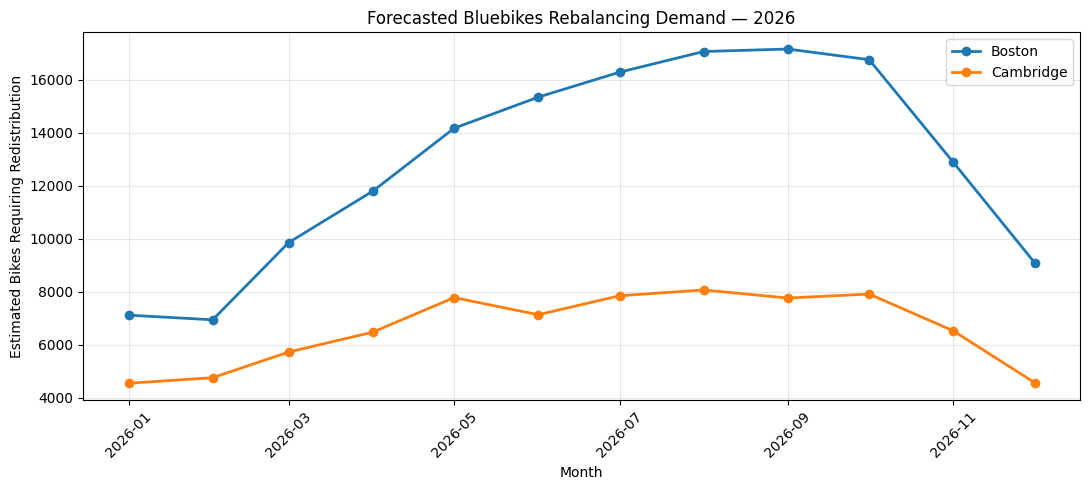

In [45]:
# DEMO CELL

# Focus on Boston and Cambridge
plot_data = forecast_2026[
    forecast_2026["city"].isin(["Boston", "Cambridge"])
].copy()

# Convert month numbers into dates
plot_data["date"] = pd.to_datetime(
    plot_data["month"], format="%Y%m"
)

# Create the chart
plt.figure(figsize=(11, 5))

for city in ["Boston", "Cambridge"]:
    city_data = plot_data[
        plot_data["city"] == city
    ].sort_values("date")

    plt.plot(
        city_data["date"],
        city_data["forecast_bikes"],
        marker="o",
        linewidth=2,
        label=city
    )

plt.title("Forecasted Bluebikes Rebalancing Demand — 2026")
plt.xlabel("Month")
plt.ylabel("Estimated Bikes Requiring Redistribution")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3. Staffing and Cost Analysis

In [11]:
# Project assumptions
BIKES_PER_SHIFT = 120
SHIFTS_PER_WEEK = 6

# Make a copy of our forecast
staffing = forecast_2026.copy()

# Convert month into a date
staffing["date"] = pd.to_datetime(
    staffing["month"], format="%Y%m"
)

# Determine number of days in each month
staffing["days_in_month"] = staffing["date"].dt.days_in_month

# Estimate how many shifts one crew works each month
staffing["shifts_per_crew"] = (
    staffing["days_in_month"] * SHIFTS_PER_WEEK / 7
)

# Calculate monthly bike-moving capacity per crew
staffing["monthly_crew_capacity"] = (
    staffing["shifts_per_crew"] * BIKES_PER_SHIFT
)

# Calculate minimum number of crews needed
staffing["crews_needed"] = np.ceil(
    staffing["forecast_bikes"] /
    staffing["monthly_crew_capacity"]
).astype(int)

print("Monthly staffing requirements:")
display(
    staffing[
        ["month", "city", "forecast_bikes",
         "monthly_crew_capacity", "crews_needed"]
    ].head(20)
)

Monthly staffing requirements:


year,month,city,forecast_bikes,monthly_crew_capacity,crews_needed
0,202601,Arlington,116,3188.571429,1
1,202601,Boston,7120,3188.571429,3
2,202601,Brookline,534,3188.571429,1
3,202601,Cambridge,4548,3188.571429,2
4,202601,Chelsea,40,3188.571429,1
5,202601,Everett,157,3188.571429,1
6,202601,Malden,53,3188.571429,1
7,202601,Medford,164,3188.571429,1
8,202601,Newton,31,3188.571429,1
9,202601,Revere,27,3188.571429,1


In [12]:
# Starting full-time crews
existing_crews = {
    "Boston": 6,
    "Cambridge": 4,
    "Somerville": 1,
    "Brookline": 1
}

# Calculate peak staffing requirements for each city
peak_staffing = (
    staffing.groupby("city")
    .agg(
        minimum_crews=("crews_needed", "min"),
        maximum_crews=("crews_needed", "max"),
        average_crews=("crews_needed", "mean"),
        annual_bike_demand=("forecast_bikes", "sum")
    )
    .reset_index()
)

# Add existing crews where known
peak_staffing["existing_crews"] = (
    peak_staffing["city"].map(existing_crews)
)

# Compare peak demand against existing crews
peak_staffing["additional_crews_at_peak"] = (
    peak_staffing["maximum_crews"]
    - peak_staffing["existing_crews"]
).clip(lower=0)

# Display four main municipalities
main_city_staffing = peak_staffing[
    peak_staffing["city"].isin(existing_crews)
].sort_values("annual_bike_demand", ascending=False)

print("2026 Peak Staffing Requirements:")
display(main_city_staffing)

# Show monthly requirements for Boston and Cambridge
monthly_crew_table = staffing[
    staffing["city"].isin(["Boston", "Cambridge"])
].pivot(
    index="month",
    columns="city",
    values="crews_needed"
)

print("\nMonthly Crew Requirements:")
display(monthly_crew_table)

2026 Peak Staffing Requirements:


,city,minimum_crews,maximum_crews,average_crews,annual_bike_demand,existing_crews,additional_crews_at_peak
1,Boston,3,6,4.666667,154548,6.0,0.0
3,Cambridge,2,3,2.666667,79139,4.0,0.0
11,Somerville,1,1,1.000000,26645,1.0,0.0
2,Brookline,1,1,1.000000,7535,1.0,0.0



Monthly Crew Requirements:


city,Boston,Cambridge
month,,
202601,3,2
202602,3,2
202603,4,2
202604,4,3
202605,5,3
202606,5,3
202607,6,3
202608,6,3
202609,6,3


In [13]:
FULL_TIME_MONTHLY_COST = 54000 / 12 + 1500
SEASONAL_MONTHLY_COST = 7800
RELEASE_COST = 54000 * 0.25

existing_crews = {
    "Boston": 6,
    "Cambridge": 4,
    "Somerville": 1,
    "Brookline": 1
}

# Create a baseline plan for the four main cities
baseline = staffing[
    staffing["city"].isin(existing_crews)
].copy()

# Retain all existing full-time crews
baseline["full_time_crews"] = (
    baseline["city"].map(existing_crews)
)

# No seasonal crews in our starting scenario
baseline["seasonal_crews"] = 0

baseline["total_crews"] = (
    baseline["full_time_crews"]
    + baseline["seasonal_crews"]
)

# Calculate monthly costs
baseline["monthly_cost"] = (
    baseline["full_time_crews"] * FULL_TIME_MONTHLY_COST
    + baseline["seasonal_crews"] * SEASONAL_MONTHLY_COST
)

# Check whether each city has enough crews
baseline["crew_shortage"] = (
    baseline["crews_needed"] - baseline["total_crews"]
).clip(lower=0)

# Summarize by municipality
baseline_summary = (
    baseline.groupby("city")
    .agg(
        annual_cost=("monthly_cost", "sum"),
        peak_crews_needed=("crews_needed", "max"),
        existing_crews=("full_time_crews", "first"),
        months_understaffed=("crew_shortage",
                             lambda x: (x > 0).sum())
    )
    .reset_index()
)

print("Baseline Staffing Plan — Four Main Cities")
display(baseline_summary)

print("\nTotal annual cost:",
      f"${baseline_summary['annual_cost'].sum():,.0f}")

print("Monthly full-time crew cost:",
      f"${FULL_TIME_MONTHLY_COST:,.0f}")

print("Full-time crew release cost:",
      f"${RELEASE_COST:,.0f}")

Baseline Staffing Plan — Four Main Cities


,city,annual_cost,peak_crews_needed,existing_crews,months_understaffed
0,Boston,432000.0,6,6,0
1,Brookline,72000.0,1,1,0
2,Cambridge,288000.0,3,4,0
3,Somerville,72000.0,1,1,0



Total annual cost: $864,000
Monthly full-time crew cost: $6,000
Full-time crew release cost: $13,500


Implementation note: ChatGPT assisted with refining the code in this section. The implementation was tested and its results reviewed in Google Colab.

In [46]:
# DEMO CELL

# Start with our existing baseline
optimized = baseline.copy()

# Identify Cambridge from February onward
cambridge_reduction = (
    (optimized["city"] == "Cambridge") &
    (optimized["month"] >= "202602")
)

# Reduce Cambridge's full-time staffing from 4 to 3
optimized.loc[
    cambridge_reduction, "full_time_crews"
] = 3

# Recalculate total available crews
optimized["total_crews"] = (
    optimized["full_time_crews"]
    + optimized["seasonal_crews"]
)

# Recalculate monthly staffing costs
optimized["monthly_cost"] = (
    optimized["full_time_crews"] * FULL_TIME_MONTHLY_COST
    + optimized["seasonal_crews"] * SEASONAL_MONTHLY_COST
)

# Add one-time release cost in February
optimized["release_cost"] = 0.0

optimized.loc[
    (optimized["city"] == "Cambridge") &
    (optimized["month"] == "202602"),
    "release_cost"
] = RELEASE_COST

optimized["total_monthly_cost"] = (
    optimized["monthly_cost"] + optimized["release_cost"]
)

# Check coverage after the reduction
optimized["crew_shortage"] = (
    optimized["crews_needed"]
    - optimized["total_crews"]
).clip(lower=0)

# Compare the two scenarios
baseline_cost = baseline["monthly_cost"].sum()
optimized_cost = optimized["total_monthly_cost"].sum()
savings = baseline_cost - optimized_cost

print("SCENARIO COMPARISON")
print(f"Scenario A — Retain all crews: ${baseline_cost:,.0f}")
print(f"Scenario B — Release one crew: ${optimized_cost:,.0f}")
print(f"Annual savings: ${savings:,.0f}")

print("\nMonths with staffing shortages:",
      (optimized["crew_shortage"] > 0).sum())

display(
    optimized[optimized["city"] == "Cambridge"][
        ["month", "crews_needed", "full_time_crews",
         "release_cost", "total_monthly_cost"]
    ]
)

SCENARIO COMPARISON
Scenario A — Retain all crews: $864,000
Scenario B — Release one crew: $811,500
Annual savings: $52,500

Months with staffing shortages: 0


year,month,crews_needed,full_time_crews,release_cost,total_monthly_cost
3,202601,2,4,0.0,24000.0
16,202602,2,3,13500.0,31500.0
29,202603,2,3,0.0,18000.0
42,202604,3,3,0.0,18000.0
55,202605,3,3,0.0,18000.0
68,202606,3,3,0.0,18000.0
81,202607,3,3,0.0,18000.0
94,202608,3,3,0.0,18000.0
107,202609,3,3,0.0,18000.0
120,202610,3,3,0.0,18000.0


Implementation note: ChatGPT assisted with refining the code in this section. The implementation was tested and its results reviewed in Google Colab.

## 4. Backtesting and Sensitivity Analysis

In [15]:
# Download and process January-August 2026
actual_months = []
failed_actual_months = []

for month in range(1, 9):
    month_id = f"2026{month:02d}"

    try:
        result = process_month(2026, month)
        actual_months.append(result)
        print(f"Completed actual data: {month_id}")

    except Exception as e:
        failed_actual_months.append(month_id)
        print(f"FAILED {month_id}: {e}")

# Combine actual monthly demand
actual_2026 = pd.concat(
    actual_months, ignore_index=True
)

# Rename columns to distinguish actual from forecast
actual_2026 = actual_2026.rename(
    columns={
        "estimated_bikes_to_move": "actual_bikes"
    }
)

# Compare actual demand to our original forecast
backtest = forecast_2026.merge(
    actual_2026[["month", "city", "actual_bikes"]],
    on=["month", "city"],
    how="inner"
)

# Calculate prediction errors
backtest["error"] = (
    backtest["forecast_bikes"]
    - backtest["actual_bikes"]
)

backtest["absolute_error"] = backtest["error"].abs()

backtest["percentage_error"] = np.where(
    backtest["actual_bikes"] > 0,
    backtest["absolute_error"] / backtest["actual_bikes"] * 100,
    np.nan
)

# Calculate overall evaluation metrics
mae = backtest["absolute_error"].mean()

wape = (
    backtest["absolute_error"].sum()
    / backtest["actual_bikes"].sum()
    * 100
)

print("\nBACKTEST RESULTS")
print("Months processed:", len(actual_months))
print("Failed months:", failed_actual_months)
print(f"Mean Absolute Error: {mae:.1f} bikes")
print(f"Weighted Absolute Percentage Error: {wape:.2f}%")

# Show Boston and Cambridge results
display(
    backtest[
        backtest["city"].isin(["Boston", "Cambridge"])
    ][
        ["month", "city", "forecast_bikes",
         "actual_bikes", "percentage_error"]
    ].sort_values(["month", "city"])
)

Completed actual data: 202601
Completed actual data: 202602
Completed actual data: 202603
Completed actual data: 202604
Completed actual data: 202605
Completed actual data: 202606
Completed actual data: 202607
Completed actual data: 202608

BACKTEST RESULTS
Months processed: 8
Failed months: []
Mean Absolute Error: 290.6 bikes
Weighted Absolute Percentage Error: 14.44%


,month,city,forecast_bikes,actual_bikes,percentage_error
1,202601,Boston,7120,8217.0,13.350371
3,202601,Cambridge,4548,4154.0,9.484834
14,202602,Boston,6945,7003.0,0.828216
16,202602,Cambridge,4759,4283.0,11.113705
27,202603,Boston,9860,11878.0,16.989392
29,202603,Cambridge,5728,5826.0,1.682115
40,202604,Boston,11801,14962.0,21.126855
42,202604,Cambridge,6479,6790.0,4.580265
53,202605,Boston,14178,18178.0,22.004621
55,202605,Cambridge,7784,7352.0,5.875952


In [47]:
# DEMO CELL

# Compare actual 2026 demand against our optimized plan
coverage = optimized.merge(
    backtest[["month", "city", "actual_bikes"]],
    on=["month", "city"],
    how="inner"
)

# Calculate crews required for observed demand
coverage["actual_crews_needed"] = np.ceil(
    coverage["actual_bikes"] /
    coverage["monthly_crew_capacity"]
).astype(int)

# Check whether our planned crews were sufficient
coverage["actual_crew_shortage"] = (
    coverage["actual_crews_needed"] -
    coverage["total_crews"]
).clip(lower=0)

# Estimate bikes beyond available capacity
coverage["capacity_bikes"] = (
    coverage["total_crews"] *
    coverage["monthly_crew_capacity"]
)

coverage["uncovered_bikes"] = (
    coverage["actual_bikes"] -
    coverage["capacity_bikes"]
).clip(lower=0)

# Flag months where staffing was insufficient
coverage["understaffed"] = (
    coverage["actual_crew_shortage"] > 0
)

print("ACTUAL STAFFING COVERAGE: JAN-AUG 2026")

display(
    coverage[
        ["month", "city", "total_crews",
         "actual_crews_needed", "actual_crew_shortage",
         "uncovered_bikes"]
    ].sort_values(["month", "city"])
)

print("\nSUMMARY")
print("Understaffed city-months:", coverage["understaffed"].sum())
print("Total uncovered bikes (capacity proxy):",
      round(coverage["uncovered_bikes"].sum()))

print("\nCities with understaffing:")
display(
    coverage.groupby("city")["understaffed"]
    .sum()
    .reset_index(name="understaffed_months")
)

ACTUAL STAFFING COVERAGE: JAN-AUG 2026


,month,city,total_crews,actual_crews_needed,actual_crew_shortage,uncovered_bikes
0,202601,Boston,6,3,0,0.000000
1,202601,Brookline,1,1,0,0.000000
2,202601,Cambridge,4,2,0,0.000000
3,202601,Somerville,1,1,0,0.000000
4,202602,Boston,6,3,0,0.000000
5,202602,Brookline,1,1,0,0.000000
6,202602,Cambridge,3,2,0,0.000000
7,202602,Somerville,1,1,0,0.000000
8,202603,Boston,6,4,0,0.000000
9,202603,Brookline,1,1,0,0.000000



SUMMARY
Understaffed city-months: 3
Total uncovered bikes (capacity proxy): 3506

Cities with understaffing:


,city,understaffed_months
0,Boston,3
1,Brookline,0
2,Cambridge,0
3,Somerville,0


In [17]:
# Start with our existing optimized staffing plan
seasonal_plan = optimized.copy()

# Retrospective scenario: add one seasonal Boston crew, June-August
summer_boston = (
    (seasonal_plan["city"] == "Boston") &
    (seasonal_plan["month"].isin(["202606", "202607", "202608"]))
)

seasonal_plan.loc[summer_boston, "seasonal_crews"] = 1

# Recalculate total crew capacity
seasonal_plan["total_crews"] = (
    seasonal_plan["full_time_crews"] +
    seasonal_plan["seasonal_crews"]
)

# Calculate costs including seasonal contracts
seasonal_plan["total_monthly_cost"] = (
    seasonal_plan["full_time_crews"] * FULL_TIME_MONTHLY_COST +
    seasonal_plan["seasonal_crews"] * SEASONAL_MONTHLY_COST +
    seasonal_plan["release_cost"]
)

# Test against observed January-August demand
seasonal_coverage = seasonal_plan.merge(
    backtest[["month", "city", "actual_bikes"]],
    on=["month", "city"],
    how="inner"
)

# Test three demand scenarios
results = []

for scenario, multiplier in [
    ("20% lower", 0.8),
    ("Actual demand", 1.0),
    ("20% higher", 1.2)
]:
    test = seasonal_coverage.copy()

    test["scenario_demand"] = (
        test["actual_bikes"] * multiplier
    )

    test["available_capacity"] = (
        test["total_crews"] *
        test["monthly_crew_capacity"]
    )

    test["uncovered_bikes"] = (
        test["scenario_demand"] -
        test["available_capacity"]
    ).clip(lower=0)

    results.append({
        "scenario": scenario,
        "understaffed_city_months": int(
            (test["uncovered_bikes"] > 0).sum()
        ),
        "uncovered_bikes": round(
            test["uncovered_bikes"].sum()
        )
    })

sensitivity_results = pd.DataFrame(results)

print("SEASONAL STAFFING SENSITIVITY ANALYSIS")
display(sensitivity_results)

print("\n2026 annual cost of seasonal scenario:")
print(f"${seasonal_plan['total_monthly_cost'].sum():,.0f}")

print("\nBoston seasonal contract cost:")
print(f"${3 * SEASONAL_MONTHLY_COST:,.0f}")

print("\nPeak seasonal crews operating at once:")
print(seasonal_plan.groupby("month")["seasonal_crews"].sum().max())

SEASONAL STAFFING SENSITIVITY ANALYSIS


,scenario,understaffed_city_months,uncovered_bikes
0,20% lower,0,0
1,Actual demand,0,0
2,20% higher,8,10562



2026 annual cost of seasonal scenario:
$834,900

Boston seasonal contract cost:
$23,400

Peak seasonal crews operating at once:
1


## 5. Event Analysis

In [18]:
%pip -q install -U langchain-core langchain-openai pydantic

from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel, Field
from google.colab import userdata

print("GenAI libraries installed successfully!")

GenAI libraries installed successfully!


In [19]:
import os

# Retrieve the API key securely from Colab Secrets
api_key = userdata.get("OPENAI_API_KEY")

# Make the key available to LangChain
os.environ["OPENAI_API_KEY"] = api_key

# Initialize the language model
llm = ChatOpenAI(
    model="gpt-4.1-mini",
    temperature=0
)

print("OpenAI model initialized successfully!")

OpenAI model initialized successfully!


Implementation note: ChatGPT assisted with refining the code in this section. The implementation was tested and its results reviewed in Google Colab.

In [20]:
from typing import Optional
from pydantic import BaseModel, Field

class EventInfo(BaseModel):
    event_name: str = Field(
        description="Name of the event"
    )

    event_date: str = Field(
        description="Event date in YYYY-MM-DD format"
    )

    location: str = Field(
        description="Location or neighborhood of the event"
    )

    expected_attendance: Optional[int] = Field(
        description="Expected attendance if explicitly provided",
        default=None
    )

    impact_level: str = Field(
        description="Expected bike demand impact: low, medium, or high"
    )

    reasoning: str = Field(
        description="Brief explanation of the expected impact"
    )

print("Event schema created successfully!")

Event schema created successfully!


In [21]:
prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        """You are an event analyst for the Bluebikes
        bicycle-sharing system in Greater Boston.

        Extract event information from the supplied text.

        Rules:
        - Do not invent dates, locations, or attendance.
        - If attendance is missing, return null.
        - Classify potential bike-sharing demand impact
          as low, medium, or high.
        - Explain your assessment briefly.
        - Treat event impact as an estimate, not a fact.
        - Use only the information supplied by the user."""
    ),
    (
        "human",
        "{event_description}"
    )
])

# Require the model to return our EventInfo structure
structured_llm = llm.with_structured_output(EventInfo)

# Build the LangChain workflow
event_chain = prompt | structured_llm

print("Event analysis chain created successfully!")

Event analysis chain created successfully!


In [48]:
# DEMO CELL

event_description = """
The Boston Marathon will take place on April 20, 2026.
Large crowds are expected near Kenmore Square and Back Bay,
which may affect transportation and bicycle-sharing demand.
"""

try:
    event_result = event_chain.invoke({
        "event_description": event_description
    })

    print("AI EVENT ANALYSIS")
    print(event_result.model_dump_json(indent=2))

except Exception as e:
    print("Event analysis failed:", str(e))

AI EVENT ANALYSIS
{
  "event_name": "Boston Marathon",
  "event_date": "2026-04-20",
  "location": "Kenmore Square and Back Bay",
  "expected_attendance": null,
  "impact_level": "high",
  "reasoning": "The Boston Marathon attracts large crowds near Kenmore Square and Back Bay, likely increasing demand for bike-sharing due to transportation disruptions and high attendance."
}


In [23]:
# Illustrative one-day demand adjustments
EVENT_MULTIPLIERS = {
    "low": 0.05,
    "medium": 0.20,
    "high": 0.50
}

# Use structured information extracted by our AI
event_month = pd.to_datetime(
    event_result.event_date
).strftime("%Y%m")

event_impact = EVENT_MULTIPLIERS.get(
    event_result.impact_level.lower(), 0
)

# Use Boston for this demonstration.
# A real application would map the extracted location
# to municipalities using validated geographic data.
event_city = "Boston"

# Find the relevant city's monthly forecast
event_forecast = forecast_2026[
    (forecast_2026["month"] == event_month) &
    (forecast_2026["city"] == event_city)
].copy()

if event_forecast.empty:
    print("No forecast found for this event city and month.")
else:
    # Convert monthly demand into average daily demand
    event_date = pd.to_datetime(event_result.event_date)
    days_in_month = event_date.days_in_month

    event_forecast["average_daily_demand"] = (
        event_forecast["forecast_bikes"] / days_in_month
    )

    # Estimate additional bike movements on event day
    event_forecast["additional_bikes"] = np.ceil(
        event_forecast["average_daily_demand"] * event_impact
    ).astype(int)

    # Add the assumed event impact to monthly demand
    event_forecast["adjusted_forecast"] = (
        event_forecast["forecast_bikes"] +
        event_forecast["additional_bikes"]
    )

    print("EVENT-AWARE DEMAND SCENARIO")
    print("Event:", event_result.event_name)
    print("Impact classification:", event_result.impact_level)
    print("Assumed one-day demand increase:",
          f"{event_impact * 100:.0f}%")

    display(event_forecast[
        ["month", "city", "forecast_bikes",
         "additional_bikes", "adjusted_forecast"]
    ])

EVENT-AWARE DEMAND SCENARIO
Event: Boston Marathon
Impact classification: high
Assumed one-day demand increase: 50%


year,month,city,forecast_bikes,additional_bikes,adjusted_forecast
40,202604,Boston,11801,197,11998


In [24]:
# Find the original staffing plan for the event city/month
event_staffing = staffing[
    (staffing["month"] == event_month) &
    (staffing["city"] == event_city)
].copy()

# Bring in our AI-adjusted demand forecast
event_staffing = event_staffing.merge(
    event_forecast[
        ["month", "city", "adjusted_forecast"]
    ],
    on=["month", "city"],
    how="inner"
)

# Calculate crew requirements after the event adjustment
event_staffing["adjusted_crews_needed"] = np.ceil(
    event_staffing["adjusted_forecast"] /
    event_staffing["monthly_crew_capacity"]
).astype(int)

# Compare original and adjusted crew requirements
event_staffing["additional_crews_needed"] = (
    event_staffing["adjusted_crews_needed"] -
    event_staffing["crews_needed"]
).clip(lower=0)

print("GENAI-ADJUSTED STAFFING RECOMMENDATION")

display(
    event_staffing[
        ["month", "city", "forecast_bikes",
         "adjusted_forecast", "crews_needed",
         "adjusted_crews_needed", "additional_crews_needed"]
    ]
)

# Explain the result
additional_crews = int(
    event_staffing["additional_crews_needed"].iloc[0]
)

if additional_crews > 0:
    print(
        f"\nRecommendation: Consider {additional_crews} "
        "additional crew(s) for this month."
    )
else:
    print(
        "\nRecommendation: No additional monthly crews "
        "required under this event scenario."
    )

GENAI-ADJUSTED STAFFING RECOMMENDATION


year,month,city,forecast_bikes,adjusted_forecast,crews_needed,adjusted_crews_needed,additional_crews_needed
0,202604,Boston,11801,11998,4,4,0



Recommendation: No additional monthly crews required under this event scenario.


## 6. Additional Analysis and Final Evaluation

In [25]:
main_cities = ["Boston", "Cambridge", "Somerville", "Brookline"]

# Separate smaller municipalities
smaller_cities = staffing[
    ~staffing["city"].isin(main_cities)
].copy()

# Summarize annual demand and peak staffing requirements
small_city_summary = (
    smaller_cities.groupby("city")
    .agg(
        annual_demand=("forecast_bikes", "sum"),
        peak_crews_needed=("crews_needed", "max"),
        total_crew_months=("crews_needed", "sum")
    )
    .reset_index()
    .sort_values("annual_demand", ascending=False)
)

print("SMALLER MUNICIPALITIES — 2026")
display(small_city_summary)

print("\nNumber of smaller municipalities:",
      len(small_city_summary))

print("Existing shared crews: 2")

print("Minimum simultaneous crews needed at peak:",
      int(smaller_cities.groupby("month")["crews_needed"].sum().max()))

# Illustrative allocation: assign the 2 existing crews
# to the two municipalities with highest annual demand.
# Actual assignments are not specified in the brief.
assigned_cities = small_city_summary.head(2)["city"].tolist()

smaller_cities["assigned_full_time"] = (
    smaller_cities["city"].isin(assigned_cities).astype(int)
)

smaller_cities["additional_crews_needed"] = (
    smaller_cities["crews_needed"]
    - smaller_cities["assigned_full_time"]
).clip(lower=0)

print("\nIllustrative assignment of two existing crews:",
      assigned_cities)

print("Additional crew-months needed:",
      int(smaller_cities["additional_crews_needed"].sum()))

print("\nMonthly additional crews needed:")
display(
    smaller_cities.groupby("month")["additional_crews_needed"]
    .sum()
    .reset_index()
)

SMALLER MUNICIPALITIES — 2026


,city,annual_demand,peak_crews_needed,total_crew_months
2,Everett,3252,1,12
4,Medford,3111,1,12
7,Salem,2712,1,12
5,Newton,2682,1,12
0,Arlington,2279,1,12
8,Watertown,2107,1,12
3,Malden,1124,1,12
1,Chelsea,863,1,12
6,Revere,842,1,12



Number of smaller municipalities: 9
Existing shared crews: 2
Minimum simultaneous crews needed at peak: 9

Illustrative assignment of two existing crews: ['Everett', 'Medford']
Additional crew-months needed: 84

Monthly additional crews needed:


,month,additional_crews_needed
0,202601,7
1,202602,7
2,202603,7
3,202604,7
4,202605,7
5,202606,7
6,202607,7
7,202608,7
8,202609,7
9,202610,7


In [26]:
small_utilization = smaller_cities.copy()

# Estimate monthly workload as a fraction of one crew
small_utilization["crew_utilization_pct"] = (
    small_utilization["forecast_bikes"]
    / small_utilization["monthly_crew_capacity"]
    * 100
)

# Calculate average and peak utilization
utilization_summary = (
    small_utilization.groupby("city")
    .agg(
        avg_utilization_pct=("crew_utilization_pct", "mean"),
        peak_utilization_pct=("crew_utilization_pct", "max"),
        annual_demand=("forecast_bikes", "sum")
    )
    .reset_index()
    .sort_values("annual_demand", ascending=False)
)

print("SMALL MUNICIPALITY CREW UTILIZATION")
display(utilization_summary.round(2))

print("\nCities with average utilization below 10%:")
print(
    (utilization_summary["avg_utilization_pct"] < 10).sum()
)

SMALL MUNICIPALITY CREW UTILIZATION


,city,avg_utilization_pct,peak_utilization_pct,annual_demand
2,Everett,8.64,12.98,3252
4,Medford,8.27,10.79,3111
7,Salem,7.19,16.18,2712
5,Newton,7.12,10.34,2682
0,Arlington,6.06,7.91,2279
8,Watertown,5.60,7.52,2107
3,Malden,2.98,4.54,1124
1,Chelsea,2.29,3.26,863
6,Revere,2.23,3.58,842



Cities with average utilization below 10%:
9


In [27]:
september_url = (
    "https://s3.amazonaws.com/hubway-data/"
    "202609-bluebikes-tripdata.csv"
)

# Download the September CSV
sept_trips = pd.read_csv(
    september_url,
    usecols=[
        "started_at", "ended_at",
        "start_station_name", "end_station_name",
        "start_station_id", "end_station_id"
    ],
    low_memory=False
)

print("September trips loaded:", len(sept_trips))

# Prepare dates, stations, and city matches
for side, date_col in [
    ("start", "started_at"),
    ("end", "ended_at")
]:
    sept_trips[f"{side}_date"] = pd.to_datetime(
        sept_trips[date_col], errors="coerce"
    ).dt.normalize()

    sept_trips[f"{side}_key"] = (
        sept_trips[f"{side}_station_name"]
        .fillna("").str.strip().str.lower()
        .str.split().str.join(" ")
    )

    sept_trips[f"{side}_city"] = (
        sept_trips[f"{side}_key"].map(station_lookup)
    )

    sept_trips[f"{side}_city"] = (
        sept_trips[f"{side}_city"].fillna(
            sept_trips[f"{side}_station_id"].map(id_lookup)
        )
    )

# Count station pickups
sept_starts = (
    sept_trips.dropna(subset=["start_date", "start_city"])
    .groupby(["start_date", "start_city", "start_key"])
    .size().reset_index(name="pickups")
    .rename(columns={
        "start_date": "date",
        "start_city": "city",
        "start_key": "station"
    })
)

# Count station returns
sept_ends = (
    sept_trips.dropna(subset=["end_date", "end_city"])
    .groupby(["end_date", "end_city", "end_key"])
    .size().reset_index(name="returns")
    .rename(columns={
        "end_date": "date",
        "end_city": "city",
        "end_key": "station"
    })
)

# Calculate daily station deficits
sept_balance = sept_starts.merge(
    sept_ends,
    on=["date", "city", "station"],
    how="outer"
)

sept_balance[["pickups", "returns"]] = (
    sept_balance[["pickups", "returns"]].fillna(0)
)

sept_balance = sept_balance[
    sept_balance["date"].dt.strftime("%Y%m") == "202609"
]

sept_balance["bikes_needed"] = (
    sept_balance["pickups"] - sept_balance["returns"]
).clip(lower=0)

# Aggregate by city
sept_actual = (
    sept_balance.groupby("city")["bikes_needed"]
    .sum()
    .reset_index(name="actual_bikes")
)

sept_actual["month"] = "202609"

# Add September to previous actuals
actual_2026 = pd.concat(
    [actual_2026, sept_actual],
    ignore_index=True
)

# Refresh backtesting results
backtest = forecast_2026.merge(
    actual_2026[["month", "city", "actual_bikes"]],
    on=["month", "city"],
    how="inner"
)

backtest["absolute_error"] = (
    backtest["forecast_bikes"] -
    backtest["actual_bikes"]
).abs()

mae = backtest["absolute_error"].mean()

wape = (
    backtest["absolute_error"].sum()
    / backtest["actual_bikes"].sum() * 100
)

print("\nUPDATED BACKTEST: JANUARY-SEPTEMBER 2026")
print("Months evaluated:", backtest["month"].nunique())
print(f"MAE: {mae:.1f} bikes")
print(f"WAPE: {wape:.2f}%")

print("\nSeptember forecast versus actual:")
display(
    backtest[backtest["month"] == "202609"][
        ["city", "forecast_bikes", "actual_bikes",
         "absolute_error"]
    ]
)

September trips loaded: 555205

UPDATED BACKTEST: JANUARY-SEPTEMBER 2026
Months evaluated: 9
MAE: 279.2 bikes
WAPE: 13.57%

September forecast versus actual:


,city,forecast_bikes,actual_bikes,absolute_error
104,Arlington,234,307.0,73.0
105,Boston,17168,18064.0,896.0
106,Brookline,636,966.0,330.0
107,Cambridge,7766,8256.0,490.0
108,Chelsea,69,97.0,28.0
109,Everett,360,328.0,32.0
110,Malden,140,138.0,2.0
111,Medford,333,320.0,13.0
112,Newton,319,304.0,15.0
113,Revere,95,149.0,54.0


In [28]:
# Rebuild coverage using all nine months of actual data
final_coverage = seasonal_plan.merge(
    backtest[["month", "city", "actual_bikes"]],
    on=["month", "city"],
    how="inner",
    validate="one_to_one"
)

# Calculate observed-demand crew requirements
final_coverage["actual_crews_needed"] = np.ceil(
    final_coverage["actual_bikes"] /
    final_coverage["monthly_crew_capacity"]
).astype(int)

# Calculate available capacity
final_coverage["available_capacity"] = (
    final_coverage["total_crews"] *
    final_coverage["monthly_crew_capacity"]
)

# Calculate potential capacity shortages
final_coverage["uncovered_bikes"] = (
    final_coverage["actual_bikes"] -
    final_coverage["available_capacity"]
).clip(lower=0)

# Check whether staffing falls short
final_coverage["understaffed"] = (
    final_coverage["uncovered_bikes"] > 0
)

# Display summary
print("FINAL STAFFING VALIDATION — JAN-SEPT 2026")

print("Months evaluated:",
      final_coverage["month"].nunique())

print("Cities evaluated:",
      final_coverage["city"].nunique())

print("Understaffed city-months:",
      final_coverage["understaffed"].sum())

print("Estimated uncovered bike movements:",
      round(final_coverage["uncovered_bikes"].sum()))

print("\nSeptember staffing results:")

display(
    final_coverage[
        final_coverage["month"] == "202609"
    ][
        ["city", "actual_bikes",
         "actual_crews_needed", "total_crews",
         "uncovered_bikes"]
    ]
)

# Confirm the nine months are present
expected_months = {
    f"2026{m:02d}" for m in range(1, 10)
}

assert expected_months.issubset(
    set(final_coverage["month"].unique())
), "Missing one or more backtesting months!"

# Confirm seasonal staffing cap is respected
assert (
    seasonal_plan.groupby("month")["seasonal_crews"]
    .sum().max() <= 8
), "Seasonal crew limit exceeded!"

print("\nValidation checks passed!")

# Save results for project documentation
backtest.to_csv("bluebikes_backtest_2026.csv", index=False)

seasonal_plan.to_csv(
    "bluebikes_staffing_plan_2026.csv", index=False
)

FINAL STAFFING VALIDATION — JAN-SEPT 2026
Months evaluated: 9
Cities evaluated: 4
Understaffed city-months: 0
Estimated uncovered bike movements: 0

September staffing results:


,city,actual_bikes,actual_crews_needed,total_crews,uncovered_bikes
32,Boston,18064.0,6,6,0.0
33,Brookline,966.0,1,1,0.0
34,Cambridge,8256.0,3,3,0.0
35,Somerville,2032.0,1,1,0.0



Validation checks passed!


In [49]:
# DEMO CELL

sensitivity_results_final = []

for scenario, multiplier in [
    ("20% lower", 0.8),
    ("Observed demand", 1.0),
    ("20% higher", 1.2)
]:
    test = final_coverage.copy()

    test["scenario_demand"] = (
        test["actual_bikes"] * multiplier
    )

    test["uncovered_bikes"] = (
        test["scenario_demand"] -
        test["available_capacity"]
    ).clip(lower=0)

    sensitivity_results_final.append({
        "scenario": scenario,
        "understaffed_city_months": int(
            (test["uncovered_bikes"] > 0).sum()
        ),
        "uncovered_bikes": round(
            test["uncovered_bikes"].sum()
        )
    })

final_sensitivity = pd.DataFrame(
    sensitivity_results_final
)

print("FINAL SENSITIVITY ANALYSIS — JAN-SEPT 2026")
display(final_sensitivity)

print("\nFINAL PROJECT METRICS")
print(f"Forecast WAPE: {wape:.2f}%")
print(f"Forecast MAE: {mae:.1f} bikes")
print(f"Baseline annual cost: ${baseline_cost:,.0f}")
print(
    "Revised annual cost:",
    f"${seasonal_plan['total_monthly_cost'].sum():,.0f}"
)
print(
    "Potential annual savings:",
    f"${baseline_cost - seasonal_plan['total_monthly_cost'].sum():,.0f}"
)

FINAL SENSITIVITY ANALYSIS — JAN-SEPT 2026


,scenario,understaffed_city_months,uncovered_bikes
0,20% lower,0,0
1,Observed demand,0,0
2,20% higher,10,14375



FINAL PROJECT METRICS
Forecast WAPE: 13.57%
Forecast MAE: 279.2 bikes
Baseline annual cost: $864,000
Revised annual cost: $834,900
Potential annual savings: $29,100


## Project Scope and Limitations

This project uses historical Bluebikes data from 2024–2025 to predict rebalancing demand across 13 municipalities for 2026. While demand was forecasted for all 13 municipalities, the detailed staffing and cost analysis focuses on Boston, Cambridge, Somerville, and Brookline, since these cities account for most of the demand.

The other nine municipalities were included in the demand analysis, but their lower usage and restrictions on sharing crews between cities made staffing decisions more complicated.

We also compared our forecasts against actual 2026 trip data from January through September. This showed that Boston needed additional staffing during the summer, so we tested adding a seasonal crew from June through August. This adjustment was made after reviewing actual demand, rather than being part of our original forecast.

Overall, the revised plan could save approximately $29,100 annually across the four main cities. However, our estimates are based on daily differences between bike pickups and returns, rather than actual bike redistribution records. This means our model may not capture every staffing need, particularly during busy hours.